In [1]:
import keras
from keras.utils.np_utils import to_categorical # used for converting labels to one-hot-encoding
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D, BatchNormalization
from sklearn.model_selection import train_test_split
from scipy import stats
from sklearn.preprocessing import LabelEncoder
from PIL import Image
import numpy as np
import cv2
from PIL import Image, ImageChops, ImageEnhance
import os
import itertools

In [2]:
def convert_to_ela_image(path, quality):
    temp_filename = 'temp_file.jpg'
    ela_filename = 'temp_ela_file.png'

    image = Image.open(path).convert('RGB')
    image.save(temp_filename, 'JPEG', quality = quality)
    temp_image = Image.open(temp_filename)

    ela_image = ImageChops.difference(image, temp_image)

    extrema = ela_image.getextrema()
    max_diff = max([ex[1] for ex in extrema])
    if max_diff == 0:
        max_diff = 1
    scale = 255.0 / max_diff
    ela_image = ImageEnhance.Brightness(ela_image).enhance(scale)

    return ela_image

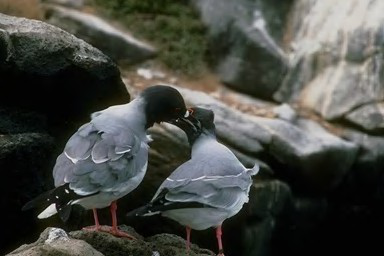

In [3]:
real_image_path = './drive/MyDrive/CASIA2/Au/Au_ani_00007.jpg'
Image.open(real_image_path)

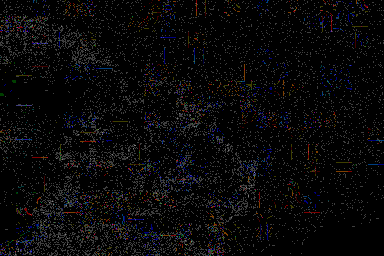

In [4]:
convert_to_ela_image(real_image_path, 98)

In [5]:
image_size = (128, 128)

def prepare_image(image_path):
    return np.array(convert_to_ela_image(image_path, 98).resize(image_size)).flatten() / 255.0

X = [] # ELA converted images
Y = [] # 0 for fake, 1 for real

In [6]:

import random
count = 0
path = './drive/MyDrive/CASIA2/Au'
for dirname, _, filenames in os.walk(path):
    for filename in filenames:
        if filename.endswith('jpg') or filename.endswith('png') or filename.endswith('tif') or filename.endswith('bmp'):
            full_path = os.path.join(dirname, filename)
            X.append(prepare_image(full_path))
            Y.append(1)

        if len(Y) % 3500 == 0:
            print(f'Processing {len(Y)} images')
            break


random.shuffle(X)
# X = X[:2100]
# Y = Y[:2100]
print(len(X), len(Y))

Processing 3500 images
3500 3500


In [7]:
len(X),len(Y)

(3500, 3500)

In [8]:
x_t, y_t = [], []
path = './drive/MyDrive/CASIA2/Tp'
count = 0
for dirname, _, filenames in os.walk(path):
    for filename in filenames:
        if filename.endswith('jpg') or filename.endswith('png') or filename.endswith('tif') or filename.endswith('bmp'):
            full_path = os.path.join(dirname, filename)
            X.append(prepare_image(full_path))
            Y.append(0)

        if len(Y) % 7000 == 0:
            print(f'Processing {len(Y)} images')
            break



print(len(X), len(Y))

Processing 7000 images
7000 7000


In [9]:
from keras.utils.np_utils import to_categorical
from sklearn.utils import shuffle
for i in range(10):
    X, Y = shuffle(X, Y, random_state=i)
X = np.array(X)
Y = to_categorical(Y, 2)
X = X.reshape(-1, 128, 128, 3)
X_train, X_val, Y_train, Y_val = train_test_split(X, Y, test_size = 0.2, random_state=42)
X = X.reshape(-1,1,1,1)
print(len(X_train), len(Y_train))
print(len(X_val), len(Y_val))

5600 5600
1400 1400


In [10]:
def build_model():
    model = Sequential()
    model.add(Conv2D(input_shape=(128,128,3),filters=64,kernel_size=(3,3),padding="same", activation="relu"))
    model.add(Conv2D(filters=64,kernel_size=(3,3),padding="same", activation="relu"))
    model.add(MaxPool2D(pool_size=(2,2),strides=(2,2)))

    model.add(Conv2D(filters=128, kernel_size=(3,3), padding="same", activation="relu"))
    model.add(Conv2D(filters=128, kernel_size=(3,3), padding="same", activation="relu"))
    model.add(MaxPool2D(pool_size=(2,2),strides=(2,2)))

    model.add(Conv2D(filters=512, kernel_size=(3,3), padding="same", activation="relu"))
    model.add(Conv2D(filters=512, kernel_size=(3,3), padding="same", activation="relu"))
    model.add(Conv2D(filters=512, kernel_size=(3,3), padding="same", activation="relu"))
    model.add(MaxPool2D(pool_size=(2,2),strides=(2,2)))

    model.add(Flatten())
    model.add(Dense(units=512,activation="relu"))
    model.add(Dense(units=256,activation="relu"))
    model.add(Dense(units=2, activation="sigmoid"))

    print(model.summary())
    return model

model = build_model()
model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 64)      1792      
                                                                 
 conv2d_1 (Conv2D)           (None, 128, 128, 64)      36928     
                                                                 
 max_pooling2d (MaxPooling2D  (None, 64, 64, 64)       0         
 )                                                               
                                                                 
 conv2d_2 (Conv2D)           (None, 64, 64, 128)       73856     
                                                                 
 conv2d_3 (Conv2D)           (None, 64, 64, 128)       147584    
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 32, 32, 128)      0         
 2D)                                                    

In [11]:
from keras.optimizers import adam_v2
init_lr = 1e-6
optimizer = adam_v2.Adam(learning_rate = init_lr, decay = init_lr/50)
model.compile(optimizer = optimizer, loss = 'binary_crossentropy', metrics = ['accuracy'])
# model1.compile(optimizer = optimizer, loss = 'binary_crossentropy', metrics = ['accuracy'])

Epoch 1/100
88/88 [==============================] - 54s 443ms/step - loss: 0.6929 - accuracy: 0.5064 - val_loss: 0.6925 - val_accuracy: 0.5793
Epoch 2/100
88/88 [==============================] - 33s 381ms/step - loss: 0.6916 - accuracy: 0.6607 - val_loss: 0.6902 - val_accuracy: 0.7286
Epoch 3/100
88/88 [==============================] - 33s 373ms/step - loss: 0.6860 - accuracy: 0.7775 - val_loss: 0.6790 - val_accuracy: 0.7821
Epoch 4/100
88/88 [==============================] - 33s 377ms/step - loss: 0.6629 - accuracy: 0.8082 - val_loss: 0.6386 - val_accuracy: 0.8129
Epoch 5/100
88/88 [==============================] - 36s 405ms/step - loss: 0.5970 - accuracy: 0.8305 - val_loss: 0.5457 - val_accuracy: 0.8379
Epoch 6/100
88/88 [==============================] - 33s 377ms/step - loss: 0.4948 - accuracy: 0.8525 - val_loss: 0.4478 - val_accuracy: 0.8557
Epoch 7/100
88/88 [==============================] - 33s 380ms/step - loss: 0.4108 - accuracy: 0.8705 - val_loss: 0.3848 - val_accuracy:

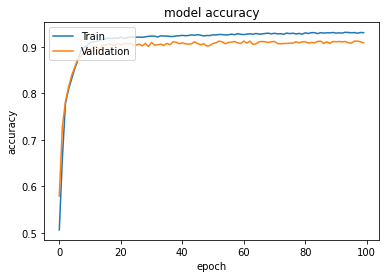

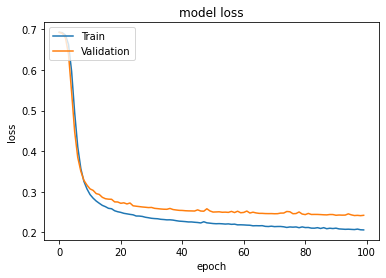

In [12]:
# Train
#You can also use generator to use augmentation during training.
batch_size = 64
epochs = 100
# X_train = np.array
history = model.fit(
    X_train, Y_train,
    epochs=epochs,
    batch_size = batch_size,
    validation_data=(X_val, Y_val),
    verbose=1)

json_file = model.to_json()
with open('./mymodel.json', "w") as file:
    file.write(json_file)
model.save("mymodel.h5")

import matplotlib.pyplot as plt

# summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()
# summarize history for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()
# score = model.evaluate(x_test, y_test)
# print('Test accuracy:', score[1])